La mayoría de los 26 bloques sirven para inspeccionar, diagnosticar y analizar los datos, pero no para limpiarlos.

##Cada parte hace

pandas: permite trabajar con tablas de datos.

numpy: nos ayudará con operaciones numéricas.

read_csv(): carga el archivo CSV.

df.shape: muestra la cantidad de filas y columnas.

head(): muestra los primeros cinco registros.

In [13]:
import pandas as pd
import numpy as np

# Cargar los partidos recopilados
df = pd.read_csv("../data/partidos_2024.csv")

print("Dataset cargado correctamente.")
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

display(df.head())

Dataset cargado correctamente.
Cantidad de filas: 3801
Cantidad de columnas: 34


,id,season,week,seasonType,startDate,startTimeTBD,completed,neutralSite,conferenceGame,attendance,...,awayConference,awayPoints,awayLineScores,awayPostgameWinProbability,awayPregameElo,awayPostgameElo,excitementIndex,highlights,notes,playoff
0,401693677,2024,1,regular,2024-08-24T04:00:00.000Z,True,True,True,False,NaN,...,NaN,45.0,"[14, 7, 14, 10]",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,401635525,2024,1,regular,2024-08-24T16:00:00.000Z,False,True,True,True,47998.0,...,ACC,21.0,"[8, 6, 0, 7]",0.065470,1692.0,1676.0,4.952562,NaN,Aer Lingus College Football Classic,NaN
2,401654665,2024,1,regular,2024-08-24T19:30:00.000Z,False,True,False,False,16125.0,...,Southland,23.0,"[7, 0, 3, 13]",0.261285,NaN,NaN,4.170973,NaN,NaN,NaN
3,401643697,2024,1,regular,2024-08-24T20:00:00.000Z,False,True,False,False,17314.0,...,Big Sky,35.0,"[0, 14, 0, 21]",0.440510,NaN,NaN,5.319335,NaN,NaN,NaN
4,401654662,2024,1,regular,2024-08-24T23:00:00.000Z,False,True,True,False,4358.0,...,UAC,15.0,"[8, 7, 0, 0]",0.020046,NaN,NaN,5.330265,NaN,FCS Kickoff,NaN


#Paso 2. Revisar la calidad de los datos

In [14]:
# Información general
df.info()

# Valores nulos
print("\nValores nulos por columna:")
display(df.isnull().sum())

# Registros duplicados
print("\nCantidad de registros duplicados:")
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3801 entries, 0 to 3800
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          3801 non-null   int64  
 1   season                      3801 non-null   int64  
 2   week                        3801 non-null   int64  
 3   seasonType                  3801 non-null   str    
 4   startDate                   3801 non-null   str    
 5   startTimeTBD                3801 non-null   bool   
 6   completed                   3801 non-null   bool   
 7   neutralSite                 3801 non-null   bool   
 8   conferenceGame              3801 non-null   bool   
 9   attendance                  1594 non-null   float64
 10  venueId                     3792 non-null   float64
 11  venue                       3792 non-null   str    
 12  homeId                      3801 non-null   int64  
 13  homeTeam                    3801 non-null   

id                               0
season                           0
week                             0
seasonType                       0
startDate                        0
startTimeTBD                     0
completed                        0
neutralSite                      0
conferenceGame                   0
attendance                    2207
venueId                          9
venue                            9
homeId                           0
homeTeam                         0
homeClassification              17
homeConference                  17
homePoints                       2
homeLineScores                   2
homePostgameWinProbability    2185
homePregameElo                2881
homePostgameElo               2882
awayId                           0
awayTeam                         0
awayClassification              54
awayConference                  54
awayPoints                       2
awayLineScores                   2
awayPostgameWinProbability    2185
awayPregameElo      


Cantidad de registros duplicados:
0


#Comprobaremos tres cosas:

1. Tipos de datos: si las columnas contienen números, fechas o texto.
2. Valores nulos: si existen datos faltantes.
3. Duplicados: si tenemos partidos repetidos.

In [15]:
# Calculamos la cantidad de valores nulos por columna
cantidad_nulos = df.isnull().sum()

# Calculamos el porcentaje de valores nulos
porcentaje_nulos = (df.isnull().mean() * 100).round(2)

# Creamos un resumen
resumen_nulos = pd.DataFrame({
    'Cantidad de nulos': cantidad_nulos,
    'Porcentaje (%)': porcentaje_nulos
})

# Ordenamos de mayor a menor
resumen_nulos = resumen_nulos.sort_values(
    by='Porcentaje (%)',
    ascending=False
)

display(resumen_nulos)

,Cantidad de nulos,Porcentaje (%)
highlights,3801,100.00
playoff,3790,99.71
notes,3641,95.79
awayPostgameElo,3003,79.01
awayPregameElo,3002,78.98
homePostgameElo,2882,75.82
homePregameElo,2881,75.80
attendance,2207,58.06
homePostgameWinProbability,2185,57.48
awayPostgameWinProbability,2185,57.48


##PROBAR

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.isnull().sum()

id                               0
season                           0
week                             0
seasonType                       0
startDate                        0
startTimeTBD                     0
completed                        0
neutralSite                      0
conferenceGame                   0
attendance                    2207
venueId                          9
venue                            9
homeId                           0
homeTeam                         0
homeClassification              17
homeConference                  17
homePoints                       2
homeLineScores                   2
homePostgameWinProbability    2185
homePregameElo                2881
homePostgameElo               2882
awayId                           0
awayTeam                         0
awayClassification              54
awayConference                  54
awayPoints                       2
awayLineScores                   2
awayPostgameWinProbability    2185
awayPregameElo      

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3801 entries, 0 to 3800
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          3801 non-null   int64  
 1   season                      3801 non-null   int64  
 2   week                        3801 non-null   int64  
 3   seasonType                  3801 non-null   str    
 4   startDate                   3801 non-null   str    
 5   startTimeTBD                3801 non-null   bool   
 6   completed                   3801 non-null   bool   
 7   neutralSite                 3801 non-null   bool   
 8   conferenceGame              3801 non-null   bool   
 9   attendance                  1594 non-null   float64
 10  venueId                     3792 non-null   float64
 11  venue                       3792 non-null   str    
 12  homeId                      3801 non-null   int64  
 13  homeTeam                    3801 non-null   

In [19]:
df.describe()

,id,season,week,attendance,venueId,homeId,homePoints,homePostgameWinProbability,homePregameElo,homePostgameElo,awayId,awayPoints,awayPostgameWinProbability,awayPregameElo,awayPostgameElo,excitementIndex,highlights
count,3.801000e+03,3801.0,3801.000000,1594.000000,3792.000000,3801.000000,3799.000000,1616.000000,920.000000,919.000000,3801.000000,3799.000000,1616.000000,799.000000,798.000000,1617.000000,0.0
mean,4.016616e+08,2024.0,7.133386,27186.951066,4773.591772,4748.468824,28.659911,0.623612,1521.800000,1529.574538,5445.898185,23.945512,0.376388,1500.569462,1491.532581,4.485326,NaN
std,2.242464e+04,0.0,3.788187,27110.477000,1321.369620,19082.969002,15.845976,0.395112,236.620436,241.553394,20910.332495,14.731025,0.395112,238.184007,245.685436,1.814760,NaN
min,4.016283e+08,2024.0,1.000000,453.000000,36.000000,2.000000,0.000000,0.000000,835.000000,805.000000,2.000000,0.000000,0.000000,805.000000,760.000000,1.064610,NaN
25%,4.016387e+08,2024.0,4.000000,6282.250000,3782.000000,238.000000,17.000000,0.196282,1371.000000,1372.500000,257.000000,14.000000,0.013439,1344.500000,1317.000000,3.129066,NaN
50%,4.016743e+08,2024.0,7.000000,17029.000000,4430.000000,2141.000000,28.000000,0.828316,1520.000000,1524.000000,2188.000000,22.000000,0.171684,1490.000000,1489.000000,4.217336,NaN
75%,4.016758e+08,2024.0,10.000000,41454.750000,5907.000000,2583.000000,38.000000,0.986561,1644.000000,1665.500000,2623.000000,34.000000,0.803718,1637.000000,1633.000000,5.654924,NaN
max,4.017412e+08,2024.0,16.000000,111170.000000,10803.000000,129738.000000,96.000000,1.000000,2169.000000,2165.000000,129758.000000,84.000000,1.000000,2196.000000,2211.000000,27.944805,NaN


In [27]:
# Porcentaje de valores faltantes por columna
(df.isnull().mean() * 100).round(2)

id                              0.00
season                          0.00
week                            0.00
seasonType                      0.00
startDate                       0.00
startTimeTBD                    0.00
completed                       0.00
neutralSite                     0.00
conferenceGame                  0.00
attendance                     58.06
venueId                         0.24
venue                           0.24
homeId                          0.00
homeTeam                        0.00
homeClassification              0.45
homeConference                  0.45
homePoints                      0.05
homeLineScores                  0.05
homePostgameWinProbability     57.48
homePregameElo                 75.80
homePostgameElo                75.82
awayId                          0.00
awayTeam                        0.00
awayClassification              1.42
awayConference                  1.42
awayPoints                      0.05
awayLineScores                  0.05
a

In [26]:
print("DIMENSIONES:")
print(df.shape)

print("\nVALORES FALTANTES:")
print(df.isnull().sum())

print("\nPORCENTAJE DE FALTANTES:")
print((df.isnull().mean() * 100).round(2))


print("\nFILAS DUPLICADAS:")
print(df.duplicated().sum())


print("\nTIPOS DE DATOS:")
print(df.dtypes)

print("\nESTADÍSTICAS:")
print(df.describe())

DIMENSIONES:
(3801, 34)

VALORES FALTANTES:
id                               0
season                           0
week                             0
seasonType                       0
startDate                        0
startTimeTBD                     0
completed                        0
neutralSite                      0
conferenceGame                   0
attendance                    2207
venueId                          9
venue                            9
homeId                           0
homeTeam                         0
homeClassification              17
homeConference                  17
homePoints                       2
homeLineScores                   2
homePostgameWinProbability    2185
homePregameElo                2881
homePostgameElo               2882
awayId                           0
awayTeam                         0
awayClassification              54
awayConference                  54
awayPoints                       2
awayLineScores                   2
awayPostgam

In [28]:
missing = (df.isnull().mean() * 100).round(2)

for columna, porcentaje in missing.items():

    if porcentaje == 0:
        print(columna, "-> Completa")

    elif porcentaje <= 5:
        print(columna, "-> Pocos valores faltantes")

    elif porcentaje <= 50:
        print(columna, "-> Valores faltantes moderados")

    else:
        print(columna, "-> Muchos valores faltantes")

id -> Completa
season -> Completa
week -> Completa
seasonType -> Completa
startDate -> Completa
startTimeTBD -> Completa
completed -> Completa
neutralSite -> Completa
conferenceGame -> Completa
attendance -> Muchos valores faltantes
venueId -> Pocos valores faltantes
venue -> Pocos valores faltantes
homeId -> Completa
homeTeam -> Completa
homeClassification -> Pocos valores faltantes
homeConference -> Pocos valores faltantes
homePoints -> Pocos valores faltantes
homeLineScores -> Pocos valores faltantes
homePostgameWinProbability -> Muchos valores faltantes
homePregameElo -> Muchos valores faltantes
homePostgameElo -> Muchos valores faltantes
awayId -> Completa
awayTeam -> Completa
awayClassification -> Pocos valores faltantes
awayConference -> Pocos valores faltantes
awayPoints -> Pocos valores faltantes
awayLineScores -> Pocos valores faltantes
awayPostgameWinProbability -> Muchos valores faltantes
awayPregameElo -> Muchos valores faltantes
awayPostgameElo -> Muchos valores faltantes

In [29]:
df["completed"].value_counts(dropna=False)

completed
True     3799
False       2
Name: count, dtype: int64

In [30]:
df.groupby("completed")["attendance"].apply(
    lambda x: x.isnull().mean() * 100
)

completed
False    100.00000
True      58.04159
Name: attendance, dtype: float64

In [31]:
df.groupby("completed").agg(
    total_partidos=("id", "count"),
    asistencia_faltante=("attendance",
                         lambda x: x.isnull().sum()),
    puntos_local_faltantes=("homePoints",
                            lambda x: x.isnull().sum()),
    puntos_visitante_faltantes=("awayPoints",
                                lambda x: x.isnull().sum())
)

,total_partidos,asistencia_faltante,puntos_local_faltantes,puntos_visitante_faltantes
completed,,,,
False,2,2,2,2
True,3799,2205,0,0


In [32]:
df[df["completed"] == False]

,id,season,week,seasonType,startDate,startTimeTBD,completed,neutralSite,conferenceGame,attendance,...,awayConference,awayPoints,awayLineScores,awayPostgameWinProbability,awayPregameElo,awayPostgameElo,excitementIndex,highlights,notes,playoff
1274,401640992,2024,5,regular,2024-09-28T19:30:00.000Z,False,False,False,False,NaN,...,Conference USA,NaN,NaN,NaN,1846.0,NaN,NaN,NaN,NaN,NaN
2679,401677463,2024,10,regular,2024-11-02T17:00:00.000Z,False,False,True,False,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
df[df["completed"] == False][
    ["id", "week", "startDate", "homeTeam",
     "awayTeam", "homePoints", "awayPoints", "attendance"]
]

,id,week,startDate,homeTeam,awayTeam,homePoints,awayPoints,attendance
1274,401640992,5,2024-09-28T19:30:00.000Z,App State,Liberty,NaN,NaN,NaN
2679,401677463,10,2024-11-02T17:00:00.000Z,Taylor,Defiance College,NaN,NaN,NaN


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df["id"].duplicated().sum()

np.int64(0)

In [36]:
df[
    (df["homePoints"] < 0) |
    (df["awayPoints"] < 0)
]

,id,season,week,seasonType,startDate,startTimeTBD,completed,neutralSite,conferenceGame,attendance,...,awayConference,awayPoints,awayLineScores,awayPostgameWinProbability,awayPregameElo,awayPostgameElo,excitementIndex,highlights,notes,playoff


In [37]:
df[
    (df["homePostgameWinProbability"] < 0) |
    (df["homePostgameWinProbability"] > 1) |
    (df["awayPostgameWinProbability"] < 0) |
    (df["awayPostgameWinProbability"] > 1)
]

,id,season,week,seasonType,startDate,startTimeTBD,completed,neutralSite,conferenceGame,attendance,...,awayConference,awayPoints,awayLineScores,awayPostgameWinProbability,awayPregameElo,awayPostgameElo,excitementIndex,highlights,notes,playoff


In [38]:
df["week"].value_counts().sort_index()

week
1     231
2     314
3     299
4     311
5     270
6     292
7     288
8     306
9     305
10    299
11    302
12    296
13    145
14    102
15     30
16     11
Name: count, dtype: int64

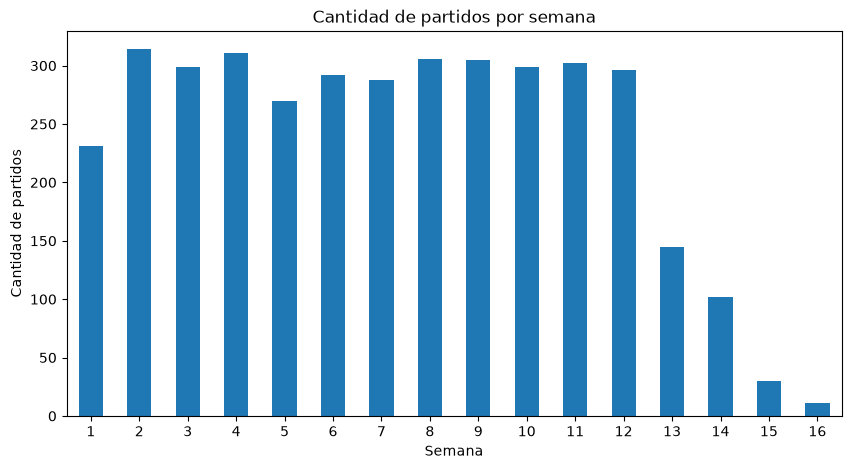

In [39]:
import matplotlib.pyplot as plt

df["week"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cantidad de partidos por semana")
plt.xlabel("Semana")
plt.ylabel("Cantidad de partidos")
plt.xticks(rotation=0)
plt.show()

In [40]:
Q1 = df["homePoints"].quantile(0.25)
Q3 = df["homePoints"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df["homePoints"] < limite_inferior) |
    (df["homePoints"] > limite_superior)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de posibles outliers:", len(outliers))

Q1: 17.0
Q3: 38.0
IQR: 21.0
Límite inferior: -14.5
Límite superior: 69.5
Cantidad de posibles outliers: 42


El método IQR considera posibles valores extremos aquellos que están por debajo de -14.5 o por encima de 69.5.

Como ya comprobamos que no hay puntuaciones negativas, nuestros 42 posibles outliers corresponden a puntuaciones superiores a 69.5.

##Investigar esos 42 partidos.


Lo estamos haciendo es:

1. Seleccionamos los 42 posibles valores extremos.
2. Mostramos los equipos involucrados.
3. Mostramos sus puntuaciones.
4. Ordenamos los resultados desde la puntuación más alta hasta la más baja.
Así podremos investigar si son resultados reales.

In [41]:
outliers[[
    "id",
    "week",
    "startDate",
    "homeTeam",
    "awayTeam",
    "homePoints",
    "awayPoints",
    "completed"
]].sort_values(
    by="homePoints",
    ascending=False
)

,id,week,startDate,homeTeam,awayTeam,homePoints,awayPoints,completed
3312,401673454,12,2024-11-16T18:00:00.000Z,Illinois College,Beloit,96.0,14.0,True
2688,401675410,10,2024-11-02T17:00:00.000Z,Virginia Union,Bluefield State,91.0,0.0,True
1237,401674638,5,2024-09-28T18:00:00.000Z,Hardin Simmons,North American,90.0,7.0,True
2712,401693680,10,2024-11-02T18:00:00.000Z,West Georgia,Lincoln (CA),88.0,12.0,True
493,401643788,3,2024-09-12T23:30:00.000Z,South Alabama,Northwestern State,87.0,10.0,True
2338,401673451,9,2024-10-26T17:00:00.000Z,Illinois College,Lawrence,84.0,0.0,True
598,401675997,3,2024-09-14T18:00:00.000Z,Bridgewater,Southern Virginia,80.0,0.0,True
1753,401674818,7,2024-10-12T17:00:00.000Z,Susquehanna,Keystone,79.0,6.0,True
2626,401674294,10,2024-11-02T17:00:00.000Z,UNC Pembroke,West Virginia Wesleyan,79.0,20.0,True
3099,401674496,11,2024-11-09T20:00:00.000Z,Southern Arkansas,Northwestern (OK),78.0,0.0,True


Por tanto, no podemos considerar estos registros incorrectos simplemente porque superen los 69.5 puntos.

Podemos concluir hasta ahora?

De los 42 registros:
- Todos aparecen como partidos completados.
- Todos tienen puntuaciones locales superiores al límite de 69.5.
- No encontramos puntuaciones negativas.
- No hay evidencia de que sean errores de captura.

Sin errores confirmados

Investiguemos si las puntuaciones coinciden con los resultados por período

Esto se llama validación de consistencia de los datos.

In [42]:
outliers[[
    "homeTeam",
    "awayTeam",
    "homePoints",
    "homeLineScores",
    "awayPoints",
    "awayLineScores"
]].head(10)

,homeTeam,awayTeam,homePoints,homeLineScores,awayPoints,awayLineScores
39,Arkansas,Arkansas-Pine Bluff,70.0,"[28, 21, 7, 14]",0.0,"[0, 0, 0, 0]"
48,Stephen F. Austin,North American,77.0,"[42, 28, 0, 7]",0.0,"[0, 0, 0, 0]"
94,Washington State,Portland State,70.0,"[22, 27, 14, 7]",30.0,"[7, 10, 6, 7]"
132,Ole Miss,Furman,76.0,"[24, 28, 21, 3]",0.0,"[0, 0, 0, 0]"
148,Auburn,Alabama A&M,73.0,"[28, 24, 14, 7]",3.0,"[0, 3, 0, 0]"
221,Indiana,Western Illinois,77.0,"[28, 14, 14, 21]",3.0,"[0, 3, 0, 0]"
340,UNLV,Utah Tech,72.0,"[28, 16, 7, 21]",14.0,"[7, 0, 7, 0]"
459,Arkansas-Pine Bluff,Arkansas Baptist,73.0,"[28, 24, 7, 14]",0.0,"[0, 0, 0, 0]"
471,Central Oklahoma,Langston,72.0,"[28, 21, 16, 7]",0.0,"[0, 0, 0, 0]"
493,South Alabama,Northwestern State,87.0,"[24, 28, 28, 7]",10.0,"[10, 0, 0, 0]"


In [44]:
outliers["homeLineScores"].apply(type).value_counts()

homeLineScores
<class 'str'>    42
Name: count, dtype: int64

In [45]:
outliers["awayLineScores"].apply(type).value_counts()

awayLineScores
<class 'str'>    42
Name: count, dtype: int64

In [46]:
outliers[
    outliers["homeLineScores"].apply(
        lambda x: isinstance(x, list) and
        any(not isinstance(i, (int, float)) for i in x)
    )
][["homeTeam", "homePoints", "homeLineScores"]]

,homeTeam,homePoints,homeLineScores


In [47]:
outliers[
    outliers["awayLineScores"].apply(
        lambda x: isinstance(x, list) and
        any(not isinstance(i, (int, float)) for i in x)
    )
][["awayTeam", "awayPoints", "awayLineScores"]]

,awayTeam,awayPoints,awayLineScores


¿Cuándo podemos decir que los datos están limpios?

Cuando hayamos comprobado estos puntos:

1. Valores nulos: identificar si existen datos faltantes y decidir cómo tratarlos.
2. Duplicados: comprobar que no haya registros repetidos.
3. Tipos de datos: verificar que cada columna tenga el tipo correcto (int, float, str, etc.).
4. Valores inconsistentes: comprobar que los datos tengan un formato coherente.
5. Outliers: identificar valores atípicos y determinar si son errores o datos legítimos.

##Ultima comprobación:

In [50]:
print("Dimensiones:", df.shape)
print("Duplicados:", df.duplicated().sum())
print("Valores nulos:", df.isnull().sum().sum())
print("Tipos de datos:")
print(df.dtypes)

Dimensiones: (3801, 34)
Duplicados: 0
Valores nulos: 31929
Tipos de datos:
id                              int64
season                          int64
week                            int64
seasonType                        str
startDate                         str
startTimeTBD                     bool
completed                        bool
neutralSite                      bool
conferenceGame                   bool
attendance                    float64
venueId                       float64
venue                             str
homeId                          int64
homeTeam                          str
homeClassification                str
homeConference                    str
homePoints                    float64
homeLineScores                    str
homePostgameWinProbability    float64
homePregameElo                float64
homePostgameElo               float64
awayId                          int64
awayTeam                          str
awayClassification                str
awayConferenc

Identificar dónde están concentrados esos valores nulos:

Estas columnas tienen muchos valores faltantes:

Las siguientes columnas tienen muy pocos valores faltantes:
- awayClassification
- awayConference
- homeClassification
- homeConference
- venueId
- venue

In [51]:
resumen_nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": (df.isnull().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos[
    resumen_nulos["Cantidad"] > 0
].sort_values(by="Cantidad", ascending=False)

display(resumen_nulos)

,Cantidad,Porcentaje
highlights,3801,100.00
playoff,3790,99.71
notes,3641,95.79
awayPostgameElo,3003,79.01
awayPregameElo,3002,78.98
homePostgameElo,2882,75.82
homePregameElo,2881,75.80
attendance,2207,58.06
homePostgameWinProbability,2185,57.48
awayPostgameWinProbability,2185,57.48


3. Los valores que sí debemos revisar
Revisión necesaria
Columna	Nulos
awayPoints	2
homePoints	2
homeLineScores	2
awayLineScores	2

Son columnas importantes porque contienen los resultados de los partidos.

Código 27:

In [52]:
df[df["homePoints"].isnull() | df["awayPoints"].isnull()][
    ["id", "week", "homeTeam", "awayTeam",
     "homePoints", "awayPoints", "completed"]
]

,id,week,homeTeam,awayTeam,homePoints,awayPoints,completed
1274,401640992,5,App State,Liberty,NaN,NaN,False
2679,401677463,10,Taylor,Defiance College,NaN,NaN,False


Hay algo importante en el resultado: ambos partidos tienen completed = False.

Eso significa que no tenemos evidencia de que sean partidos terminados con resultados perdidos. Es posible que sean partidos no completados o que la API no tenga sus resultados.
Decisión de limpieza
Mi recomendación es conservarlos.

¿Por qué?
- Son registros de partidos existentes.
- No están duplicados.
- No debemos inventar sus puntuaciones.
- Podemos excluirlos posteriormente cuando analicemos resultados de partidos completados.

Código 28: comprobar los partidos no completados

In [53]:
df[df["completed"] == False][
    ["id", "homeTeam", "awayTeam", "homePoints", "awayPoints"]
]

,id,homeTeam,awayTeam,homePoints,awayPoints
1274,401640992,App State,Liberty,NaN,NaN
2679,401677463,Taylor,Defiance College,NaN,NaN


Confirmamos que son los mismos dos partidos y que ambos tienen las puntuaciones faltantes.

In [55]:
df.to_csv(
    "../data/partidos_2024_limpio.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset limpio guardado correctamente.")

Dataset limpio guardado correctamente.


In [56]:
# Trabajar solamente con partidos completados
df_eda = df[df["completed"] == True].copy()

# Crear nuestra variable objetivo
df_eda["homeWin"] = (
    df_eda["homePoints"] > df_eda["awayPoints"]
).astype(int)

# Distribución de resultados
print(df_eda["homeWin"].value_counts())

print("\nPorcentajes:")
print(df_eda["homeWin"].value_counts(normalize=True) * 100)

homeWin
1    2182
0    1617
Name: count, dtype: int64

Porcentajes:
homeWin
1    57.436167
0    42.563833
Name: proportion, dtype: float64
